# 01 — What is actually in this snapshot?

**The question.** Before any metric is defined or any conclusion drawn: what does
this Gold snapshot really contain, and which of the documented data traps are
actually present in it?

**Why it matters.** Every number in this repository — every mart, every chart on
the dashboard, every answer in the analyses that follow — is computed from these
Parquet files. Each trap below produces a *plausible-looking wrong number*
rather than an error: a league table missing a match, a player's season split in
half by a transfer, an xG total quietly doubled. None of them announce
themselves. So this notebook goes looking for each one, counts it, and writes
down the rule that the metrics layer has to follow as a result.

This is a profile, not an analysis. It answers "what is here", and the rules it
establishes are the input to everything else.

## How to read this

Every number below is computed live from the snapshot named in the next cell —
nothing is typed in by hand. The notebook runs against whatever
`GOLD_SNAPSHOT_DIR` points at, which is the full warehouse export locally and
the tiny synthetic fixture in CI, so the *committed* outputs are the real
snapshot and CI only proves the code still runs.

In [1]:
import sys
from pathlib import Path

# The repository's shared code lives in src/, next to this notebooks/ folder.
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from football_analytics import snapshot, viz

viz.apply_style()
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

snap = snapshot.open_snapshot()
print(snap.citation())
print()
print(f"source: {snap.manifest['source']}")
for table, rows in snap.row_counts.items():
    print(f"  {table:<20} {rows:>9,} rows")

Gold snapshot exported 2026-09-20T13:41:36+00:00, matches 2024-08-15 to 2026-09-19 (3,733 matches, 115,410 player events, 94,034 shots)

source: football@localhost:5432/football_dw (gold schema)
  dim_players              5,219 rows
  dim_referees               159 rows
  dim_stadiums               120 rows
  dim_teams                  122 rows
  fact_matches             3,733 rows
  fact_player_events     115,410 rows
  fact_shots              94,034 rows


## 1. Coverage — which competitions, which seasons, how complete?

The scope is the big-5 leagues (`PL`, `PD`, `BL1`, `SA`, `FL1`). A complete
season is 380 matches for the 20-team leagues and 306 for the 18-team
Bundesliga; Ligue 1 dropped to 18 teams in 2023/24, so it is 306 too.

In [2]:
coverage = snap.df(
    """
    SELECT
        season,
        competition_code,
        count(*)                                        AS matches,
        count(*) FILTER (WHERE status = 'FINISHED')      AS finished,
        min(match_date)                                  AS first_match,
        max(match_date)                                  AS last_match
    FROM fact_matches
    GROUP BY season, competition_code
    ORDER BY season, competition_code NULLS LAST
    """
)
coverage

,season,competition_code,matches,finished,first_match,last_match
0,2024/25,BL1,306,305,2024-08-23,2025-05-17
1,2024/25,FL1,306,305,2024-08-16,2025-05-17
2,2024/25,PD,380,380,2024-08-15,2025-05-25
3,2024/25,PL,380,380,2024-08-16,2025-05-25
4,2024/25,SA,380,380,2024-08-17,2025-05-25
5,2024/25,NaN,2,2,2024-11-30,2025-05-18
6,2025/26,BL1,306,306,2025-08-22,2026-05-16
7,2025/26,FL1,306,305,2025-08-15,2026-05-17
8,2025/26,PD,380,380,2025-08-15,2026-05-24
9,2025/26,PL,380,380,2025-08-15,2026-05-24


Two things to notice, and both matter later.

The rows with **no `competition_code`** are not a competition — they are the
Understat halves of fixtures the two sources dated differently (trap 13, counted
properly in section 5).

The most recent season is **in progress**, not incomplete data. Part 1's daily
schedule keeps it current, so its match count grows every time the snapshot is
re-exported. Any season-level comparison has to either exclude it or say plainly
that it is a partial season.

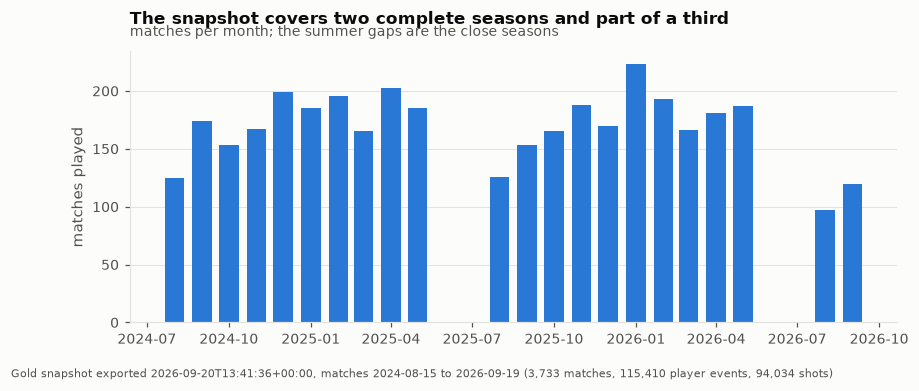

In [3]:
# The shape of the snapshot over time: where the complete seasons are, and where
# the partial one starts.
monthly = snap.df(
    """
    SELECT date_trunc('month', match_date) AS month, count(*) AS matches
    FROM fact_matches
    WHERE competition_code IS NOT NULL
    GROUP BY 1 ORDER BY 1
    """
)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(monthly["month"], monthly["matches"], width=22, color=viz.ACCENT, linewidth=0)
ax.set_ylabel("matches played")
ax.grid(axis="x", visible=False)
viz.title_block(
    ax,
    "The snapshot covers two complete seasons and part of a third",
    "matches per month; the summer gaps are the close seasons",
)
viz.annotate_source(ax, snap.citation())
plt.show()

## 2. The `Unknown` members (trap 3)

Every dimension carries a row at key `0` named `Unknown`, so a fact can always
point at *something*. `referee_key = 0` means **no referee was reported**, not a
referee named Unknown — averaging cards "per referee" without excluding it
invents an official who worked hundreds of matches.

In [4]:
unknown_usage = snap.df(
    """
    SELECT 'fact_matches.referee_key'     AS reference, count(*) AS rows_at_key_0,
           round(100.0 * count(*) / (SELECT count(*) FROM fact_matches), 2) AS pct_of_table
    FROM fact_matches WHERE referee_key = 0
    UNION ALL
    SELECT 'fact_matches.stadium_key', count(*),
           round(100.0 * count(*) / (SELECT count(*) FROM fact_matches), 2)
    FROM fact_matches WHERE stadium_key = 0
    UNION ALL
    SELECT 'fact_matches.home/away_team_key', count(*),
           round(100.0 * count(*) / (SELECT count(*) FROM fact_matches), 2)
    FROM fact_matches WHERE home_team_key = 0 OR away_team_key = 0
    UNION ALL
    SELECT 'fact_player_events.player_key', count(*),
           round(100.0 * count(*) / (SELECT count(*) FROM fact_player_events), 2)
    FROM fact_player_events WHERE player_key = 0
    UNION ALL
    SELECT 'fact_shots.player_key', count(*),
           round(100.0 * count(*) / (SELECT count(*) FROM fact_shots), 2)
    FROM fact_shots WHERE player_key = 0
    ORDER BY rows_at_key_0 DESC
    """
)
unknown_usage

,reference,rows_at_key_0,pct_of_table
0,fact_matches.referee_key,64,1.71
1,fact_matches.stadium_key,0,0.00
2,fact_player_events.player_key,0,0.00
3,fact_matches.home/away_team_key,0,0.00
4,fact_shots.player_key,0,0.00


**Rule for the metrics layer:** any per-referee or per-stadium metric filters
`key <> 0` explicitly and reports how many rows that removed. The team and
player keys are clean, so no filter is needed there — but that is a fact about
this snapshot, not a guarantee, so the dbt models test it rather than assume it.

## 3. Orphan events — the nullable `match_key` (trap 4)

`fact_player_events.match_key` and `fact_shots.match_key` are both nullable.
Understat supplied the player row or the shot, but the cross-source join never
produced a `fact_matches` row for it. An **inner join to `fact_matches` drops
these silently**, which is how a player's goal total quietly loses a goal.

In [5]:
orphans = snap.df(
    """
    SELECT 'fact_player_events' AS table_name,
           count(*) AS total_rows,
           count(*) FILTER (WHERE match_key IS NULL) AS null_match_key,
           round(100.0 * count(*) FILTER (WHERE match_key IS NULL) / count(*), 3) AS pct,
           sum(goals) FILTER (WHERE match_key IS NULL) AS goals_at_risk
    FROM fact_player_events
    UNION ALL
    SELECT 'fact_shots',
           count(*),
           count(*) FILTER (WHERE match_key IS NULL),
           round(100.0 * count(*) FILTER (WHERE match_key IS NULL) / count(*), 3),
           count(*) FILTER (WHERE match_key IS NULL AND result = 'Goal')
    FROM fact_shots
    """
)
orphans

,table_name,total_rows,null_match_key,pct,goals_at_risk
0,fact_player_events,115410,0,0.0,NaN
1,fact_shots,94034,0,0.0,0.0


**In this snapshot the count is zero.** Every player event and every shot
resolves to a match. `goals_at_risk` — what an inner join would have cost — is
nothing.

That is a fact about this export, not a property of the schema. The columns are
still nullable, Part 1 still loads Understat rows before the cross-source join
has matched them, and the split fixtures in section 5 are the same join missing
in the other direction. A future snapshot can orphan rows without warning.

**Rule for the metrics layer:** derive `season` on the event facts from their own
`match_date` (trap 5) rather than joining to `fact_matches` for it — a player
total then cannot lose rows to a join it never needed. Where a metric genuinely
needs match attributes, LEFT join and count what did not match. And because the
number above is currently zero, the dbt models *test* that it stays zero rather
than quietly tolerating a change.

## 4. Null xG is not zero (trap 7)

A null `home_xg` means Football-Data and Understat did not pair that match, not
that no chances were created. `COALESCE(xg, 0)` would score those matches 0.0 xG
and drag every average down.

In [6]:
xg_completeness = snap.df(
    """
    SELECT
        season,
        competition_code,
        count(*)                                          AS finished,
        count(*) FILTER (WHERE home_xg IS NULL)            AS missing_xg,
        round(100.0 * count(*) FILTER (WHERE home_xg IS NULL) / count(*), 2) AS pct_missing
    FROM fact_matches
    WHERE status = 'FINISHED' AND competition_code IS NOT NULL
    GROUP BY season, competition_code
    HAVING count(*) FILTER (WHERE home_xg IS NULL) > 0
    ORDER BY missing_xg DESC
    """
)
print(f"league-seasons with at least one unpaired match: {len(xg_completeness)}")
xg_completeness

league-seasons with at least one unpaired match: 5


,season,competition_code,finished,missing_xg,pct_missing
0,2025/26,FL1,305,8,2.62
1,2024/25,BL1,305,1,0.33
2,2025/26,PD,380,1,0.26
3,2026/27,FL1,39,1,2.56
4,2024/25,SA,380,1,0.26


In [7]:
# The same question asked of the whole snapshot, as one number.
overall = snap.df(
    """
    SELECT count(*) AS finished_matches,
           count(*) FILTER (WHERE home_xg IS NULL OR away_xg IS NULL) AS missing_either_xg,
           round(100.0 * count(*) FILTER (WHERE home_xg IS NULL OR away_xg IS NULL)
                 / count(*), 3) AS pct
    FROM fact_matches
    WHERE status = 'FINISHED' AND competition_code IS NOT NULL
    """
)
overall

,finished_matches,missing_either_xg,pct
0,3717,12,0.323


**Rule for the metrics layer:** xG metrics exclude null-xG matches and report the
exclusion. Because the rate is low and not concentrated in one league, an xG
average over a full season is safe — but a *per-match* xG series for a single
team has to show the gap rather than draw a line through it.

## 5. One fixture, two rows (trap 13)

When the sources disagree on the calendar date of a late kickoff, the
cross-source join misses and the fixture lands as two rows: one carrying the
result with no xG, the other carrying the xG and the player events with no result
and no `competition_code`. Counting matches per team without a filter
double-counts these.

In [8]:
split = snap.df(
    """
    SELECT season,
           count(*) FILTER (WHERE football_data_match_id IS NULL)     AS understat_only,
           count(*) FILTER (WHERE understat_match_id IS NULL)          AS football_data_only,
           count(*) FILTER (WHERE football_data_match_id IS NOT NULL
                              AND understat_match_id IS NOT NULL)      AS paired
    FROM fact_matches
    GROUP BY season ORDER BY season
    """
)
split

,season,understat_only,football_data_only,paired
0,2024/25,2,2,1750
1,2025/26,9,9,1743
2,2026/27,1,2,215


In [9]:
# The unpaired Understat halves, matched back to their Football-Data twin by the
# two clubs and a date one day either side.
twins = snap.df(
    """
    SELECT u.match_date        AS understat_date,
           f.match_date        AS football_data_date,
           h.canonical_name    AS home,
           a.canonical_name    AS away,
           f.competition_code,
           f.result,
           round(u.home_xg, 2) AS home_xg
    FROM fact_matches u
    JOIN fact_matches f
      ON f.home_team_key = u.home_team_key
     AND f.away_team_key = u.away_team_key
     AND abs(date_diff('day', f.match_date, u.match_date)) <= 1
     AND f.football_data_match_id IS NOT NULL
    JOIN dim_teams h ON h.team_key = u.home_team_key
    JOIN dim_teams a ON a.team_key = u.away_team_key
    WHERE u.football_data_match_id IS NULL
    ORDER BY u.match_date
    """
)
print(f"{len(twins)} split fixtures, each present as two rows")
twins

10 split fixtures, each present as two rows


,understat_date,football_data_date,home,away,competition_code,result,home_xg
0,2024-11-30,2024-11-29,St. Pauli,Holstein Kiel,BL1,HOME_TEAM,1.96
1,2025-05-18,2025-05-17,Genoa,Atalanta,SA,AWAY_TEAM,1.44
2,2025-09-29,2025-09-30,Valencia,Real Oviedo,PD,AWAY_TEAM,1.72
3,2026-02-08,2026-02-07,Brest,Lorient,FL1,HOME_TEAM,2.05
4,2026-02-08,2026-02-07,Lens,Rennes,FL1,HOME_TEAM,1.01
5,2026-02-08,2026-02-07,Nantes,Lyon,FL1,AWAY_TEAM,0.80
6,2026-05-03,2026-05-02,Metz,Monaco,FL1,AWAY_TEAM,1.15
7,2026-05-03,2026-05-02,Nantes,Marseille,FL1,HOME_TEAM,3.07
8,2026-05-03,2026-05-02,Nice,Lens,FL1,DRAW,1.34
9,2026-05-03,2026-05-02,Paris Saint-Germain,Lorient,FL1,DRAW,2.98


**Rule for the metrics layer:** counting matches, points or league position
filters `football_data_match_id IS NOT NULL` — the result-bearing half is the
one that belongs in a table. Player-level goal totals do *not* apply that
filter, because the goals live on the Understat half. The two rules disagree by
about 0.3%, so each mart states which one it used.

## 6. Duplicated shots (trap 14)

Understat returned every shot of a small number of matches twice, under
different shot ids. Shot counts and summed xG double there.

In [10]:
dupes = snap.df(
    """
    WITH grouped AS (
        SELECT match_key, player_key, minute, result, x, y, xg, count(*) AS copies
        FROM fact_shots
        GROUP BY ALL
        HAVING count(*) > 1
    )
    SELECT count(*)                       AS duplicated_shots,
           sum(copies)::BIGINT            AS rows_involved,
           (sum(copies) - count(*))::BIGINT AS surplus_rows,
           count(DISTINCT match_key)      AS matches_affected,
           round(sum((copies - 1) * xg), 2) AS surplus_xg
    FROM grouped
    """
)
dupes

,duplicated_shots,rows_involved,surplus_rows,matches_affected,surplus_xg
0,46,92,46,2,5.86


In [11]:
# Which matches, and how badly.
affected = snap.df(
    """
    WITH grouped AS (
        SELECT match_key, player_key, minute, result, x, y, xg, count(*) AS copies
        FROM fact_shots GROUP BY ALL HAVING count(*) > 1
    )
    SELECT m.match_date, m.competition_code, m.season,
           h.canonical_name AS home, a.canonical_name AS away,
           sum(g.copies - 1)::BIGINT AS surplus_rows
    FROM grouped g
    JOIN fact_matches m ON m.match_key = g.match_key
    JOIN dim_teams h ON h.team_key = m.home_team_key
    JOIN dim_teams a ON a.team_key = m.away_team_key
    GROUP BY ALL ORDER BY surplus_rows DESC
    """
)
affected

,match_date,competition_code,season,home,away,surplus_rows
0,2026-04-23,PD,2025/26,Real Oviedo,Villarreal,23
1,2026-09-05,PD,2026/27,Villarreal,Deportivo La Coruña,23


**Rule for the metrics layer:** `mart_shots` deduplicates on
`(match_key, player_key, minute, result, x, y, xg)`. Note that this is the
*shape* of a shot, not its id — the ids differ, which is exactly why a
`DISTINCT` on the key would not help.

## 7. Do the shot coordinates mean what we think? (trap 10)

Understat's `x` and `y` are normalized to [0, 1], but normalized *which way
round*? The check that settles it: every penalty is taken from one point on the
pitch, so if the orientation is right, all penalties collapse onto a single spot
near goal at roughly `x = 0.885, y = 0.5`.

In [12]:
geometry = snap.df(
    """
    SELECT situation,
           count(*)               AS shots,
           round(avg(x), 4)       AS avg_x,
           round(stddev(x), 4)    AS sd_x,
           round(avg(y), 4)       AS avg_y,
           round(stddev(y), 4)    AS sd_y,
           round(avg(xg), 4)      AS avg_xg
    FROM fact_shots
    WHERE x IS NOT NULL
    GROUP BY situation ORDER BY shots DESC
    """
)
geometry

,situation,shots,avg_x,sd_x,avg_y,sd_y,avg_xg
0,OpenPlay,69471,0.8484,0.0870,0.5021,0.1279,0.1215
1,FromCorner,15160,0.8828,0.0878,0.5012,0.0964,0.1005
2,SetPiece,5703,0.8671,0.0874,0.5001,0.1000,0.1104
3,DirectFreekick,2582,0.7627,0.0561,0.5113,0.1751,0.0620
4,Penalty,1118,0.8850,0.0000,0.5000,0.0000,0.7558


Penalties sit at exactly `x = 0.885, y = 0.5` with **zero** standard deviation on
both axes — one point of the pitch, as expected — and average 0.756 xG, which is
the right number for a penalty. The orientation is confirmed: higher `x` is
closer to the goal being attacked, and `y = 0.5` is the middle of the pitch.

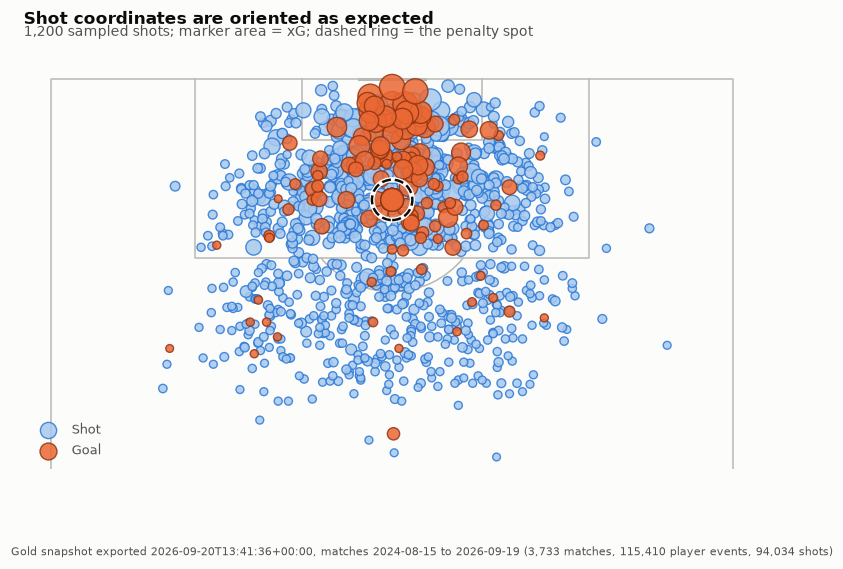

In [13]:
# The same conclusion, drawn rather than tabulated. A sample keeps the committed
# image readable; the orientation claim does not depend on which shots are shown.
shots = snap.df(
    """
    SELECT x, y, xg, result
    FROM fact_shots
    WHERE x IS NOT NULL AND match_key IS NOT NULL
    USING SAMPLE 1200 ROWS (reservoir, 42)
    """
)

fig, ax = viz.shot_map(shots, show_penalty_spot=True)
viz.title_block(
    ax,
    "Shot coordinates are oriented as expected",
    f"{len(shots):,} sampled shots; marker area = xG; dashed ring = the penalty spot",
)
viz.annotate_source(ax, snap.citation())
plt.show()

## 8. The categorical vocabularies (trap 11)

These columns hold source strings. Hardcoding a list of values without checking
it against the snapshot first is how a filter silently matches nothing.

In [14]:
for column in ("result", "situation", "shot_type"):
    values = snap.df(
        f"""
        SELECT {column} AS value, count(*) AS shots,
               round(100.0 * count(*) / (SELECT count(*) FROM fact_shots), 2) AS pct
        FROM fact_shots GROUP BY 1 ORDER BY shots DESC
        """
    )
    print(f"fact_shots.{column}")
    print(values.to_string(index=False))
    print()

fact_shots.result
      value  shots   pct
MissedShots  34102 36.27
BlockedShot  26126 27.78
  SavedShot  21490 22.85
       Goal  10159 10.80
 ShotOnPost   1857  1.97
    OwnGoal    300  0.32

fact_shots.situation
         value  shots   pct
      OpenPlay  69471 73.88
    FromCorner  15160 16.12
      SetPiece   5703  6.06
DirectFreekick   2582  2.75
       Penalty   1118  1.19

fact_shots.shot_type
        value  shots   pct
    RightFoot  46364 49.31
     LeftFoot  30624 32.57
         Head  16699 17.76
OtherBodyPart    347  0.37



Two spellings to be careful with. `MissedShots` is plural where every other
value is singular. And **`OwnGoal` is a value of `result`** — an own goal is
recorded as a shot, so `count(*) FILTER (WHERE result = 'Goal')` correctly
excludes it, but `result <> 'MissedShots'` as a proxy for "on target" would not.

## 9. Which matches count? (trap 6, and a correction to it)

The rule as originally documented was that scores are null unless
`status = 'FINISHED'`, so a results-based metric should filter on that. The first
half turns out not to be true of this snapshot, and the second half needed
sharpening — this section is the one place where the profile *changed* a rule
rather than confirming it, and `CLAUDE.md` §5 now carries the corrected version.

In [15]:
status_breakdown = snap.df(
    """
    SELECT status,
           count(*)                                     AS matches,
           count(*) FILTER (WHERE home_goals IS NULL)    AS null_score,
           count(*) FILTER (WHERE result IS NULL)        AS null_result,
           count(*) FILTER (WHERE home_xg IS NULL)       AS null_xg
    FROM fact_matches
    GROUP BY status ORDER BY matches DESC
    """
)
status_breakdown

,status,matches,null_score,null_result,null_xg
0,FINISHED,3729,0,0,12
1,AWARDED,3,0,0,0
2,POSTPONED,1,0,0,1


**No match in this snapshot has a null score.** Part 1 loads matches up to the
current date, so there are no future fixtures sitting in the table waiting to be
played — the case trap 6 warns about is real in the schema but absent from this
export.

What *is* here is four matches that are not `FINISHED`. They are not all the
same kind of thing:

In [16]:
not_finished = snap.df(
    """
    SELECT m.match_date, m.competition_code, m.season, m.status, m.result,
           m.home_goals, m.away_goals,
           h.canonical_name AS home, a.canonical_name AS away,
           m.home_xg IS NULL AS xg_missing
    FROM fact_matches m
    JOIN dim_teams h ON h.team_key = m.home_team_key
    JOIN dim_teams a ON a.team_key = m.away_team_key
    WHERE m.status <> 'FINISHED'
    ORDER BY m.match_date
    """
)
not_finished

,match_date,competition_code,season,status,result,home_goals,away_goals,home,away,xg_missing
0,2024-12-14,BL1,2024/25,AWARDED,AWAY_TEAM,0,2,Union Berlin,Bochum,False
1,2025-03-16,FL1,2024/25,AWARDED,AWAY_TEAM,0,2,Montpellier,Saint-Étienne,False
2,2026-05-17,FL1,2025/26,AWARDED,DRAW,0,0,Nantes,Toulouse,False
3,2026-09-16,PD,2026/27,POSTPONED,DRAW,0,0,Levante,Athletic Club,True


Three are **`AWARDED`**: matches abandoned and then awarded by the federation.
They were really played, they have a real score, they have xG, and they counted
towards the real league table. One is **`POSTPONED`**: it was never played, and
it carries a *phantom* `0-0` with `result = 'DRAW'` and no xG — a scoreline that
looks entirely plausible and is entirely fictional.

So `status = 'FINISHED'` does two things at once: it correctly drops the phantom,
and it incorrectly drops three real results. The cost is visible in something as
basic as how many matches a club played:

In [17]:
# In a complete 18- or 20-club season every club plays every other twice, so the
# played count is a fact we can check without any outside data.
played = snap.df(
    """
    WITH team_matches AS (
        SELECT season, competition_code, home_team_key AS team_key, status
        FROM fact_matches WHERE competition_code IS NOT NULL
        UNION ALL
        SELECT season, competition_code, away_team_key, status
        FROM fact_matches WHERE competition_code IS NOT NULL
    ),
    counted AS (
        SELECT season, competition_code, team_key,
               count(*) FILTER (WHERE status = 'FINISHED')                    AS finished_only,
               count(*) FILTER (WHERE status IN ('FINISHED', 'AWARDED'))      AS incl_awarded
        FROM team_matches GROUP BY 1, 2, 3
    )
    SELECT c.season, c.competition_code, t.canonical_name AS team,
           c.finished_only, c.incl_awarded
    FROM counted c
    JOIN dim_teams t ON t.team_key = c.team_key
    WHERE c.finished_only <> c.incl_awarded
    ORDER BY c.season, c.competition_code, t.canonical_name
    """
)
played

,season,competition_code,team,finished_only,incl_awarded
0,2024/25,BL1,Bochum,33,34
1,2024/25,BL1,Union Berlin,33,34
2,2024/25,FL1,Montpellier,33,34
3,2024/25,FL1,Saint-Étienne,33,34
4,2025/26,FL1,Nantes,33,34
5,2025/26,FL1,Toulouse,33,34


Each of those clubs was in a completed season, so each really played 34 or 38
matches. Filtering on `FINISHED` alone reports one fewer — and with it, up to
three points and a match's worth of xG.

**Rule for the metrics layer, corrected:** a results-based metric filters
`status IN ('FINISHED', 'AWARDED')`. That keeps the three awarded results and
still excludes the postponed phantom. `mart_team_season` tests the consequence
directly: in a completed season, every club's played count must equal twice the
number of opponents.

## 10. The player dimension — versions, not players (traps 1 and 2)

`dim_players` is an SCD Type 2: one row per player *version*. A player who
changed clubs has several `player_key`s, so **grouping a season by `player_key`
splits that player in two**. The durable key is `understat_player_id`.

In [18]:
versions = snap.df(
    """
    SELECT versions, count(*) AS players
    FROM (
        SELECT understat_player_id, count(*) AS versions
        FROM dim_players WHERE player_key <> 0
        GROUP BY understat_player_id
    )
    GROUP BY versions ORDER BY versions
    """
)
versions

,versions,players
0,1,3113
1,2,733
2,3,167
3,4,33
4,6,1


In [19]:
# What grouping by the wrong key actually costs. Totals span the whole
# snapshot (two seasons and part of a third), not a single season.
comparison = snap.df(
    """
    WITH by_player AS (
        SELECT understat_player_id, sum(goals) AS goals
        FROM fact_player_events GROUP BY 1
    ),
    by_version AS (
        SELECT understat_player_id, player_key, sum(goals) AS goals
        FROM fact_player_events GROUP BY 1, 2
    ),
    worst AS (
        SELECT understat_player_id, count(*) AS rows_it_would_split, max(goals) AS biggest_piece
        FROM by_version GROUP BY 1 HAVING count(*) > 1
    )
    SELECT p.player_name,
           b.goals              AS goals_by_understat_player_id,
           w.biggest_piece      AS largest_piece_by_player_key,
           w.rows_it_would_split AS pieces_it_splits_into
    FROM worst w
    JOIN by_player b USING (understat_player_id)
    JOIN dim_players p ON p.understat_player_id = w.understat_player_id AND p.is_current
    ORDER BY b.goals DESC
    LIMIT 10
    """
)
comparison

,player_name,goals_by_understat_player_id,largest_piece_by_player_key,pieces_it_splits_into
0,Jonathan Burkardt,34.0,18.0,2
1,Bryan Mbeumo,33.0,20.0,2
2,Esteban Lepaul,32.0,22.0,2
3,Donyell Malen,30.0,20.0,3
4,Luis Díaz,29.0,16.0,2
5,Alexander Isak,29.0,23.0,2
6,Antoine Semenyo,28.0,21.0,2
7,João Pedro,28.0,18.0,2
8,Moise Kean,27.0,27.0,2
9,Ferrán Torres,26.0,26.0,2


**The history caveat, which is easy to miss.** Part 1 only ever opens
`dim_players` versions going forward, so a player's earliest version begins at
their first appearance *inside the loaded range* — not at their real career
start, and not on the date they actually signed. Measured against the
snapshot's own first match date:

In [20]:
# Where does each player's FIRST recorded version begin? If valid_from were a
# career start, these would spread across many years. They do not.
first_versions = snap.df(
    f"""
    WITH bounds AS (
        SELECT DATE '{snap.first_match_date}'                  AS snapshot_start,
               DATE '{snap.first_match_date}' + INTERVAL 30 DAY AS first_month_end
    ),
    earliest AS (
        SELECT understat_player_id, min(valid_from) AS first_version
        FROM dim_players WHERE player_key <> 0
        GROUP BY understat_player_id
    )
    SELECT
        count(*)                                      AS players,
        min(e.first_version)                          AS earliest_seen,
        count(*) FILTER (WHERE e.first_version < b.snapshot_start)
                                                      AS before_snapshot_starts,
        count(*) FILTER (WHERE e.first_version < b.first_month_end)
                                                      AS in_first_30_days,
        round(100.0 * count(*) FILTER (WHERE e.first_version < b.first_month_end)
              / count(*), 1)                          AS pct_in_first_30_days
    FROM earliest e CROSS JOIN bounds b
    """
)
print(f"snapshot begins {snap.first_match_date}")
first_versions

snapshot begins 2024-08-15


,players,earliest_seen,before_snapshot_starts,in_first_30_days,pct_in_first_30_days
0,4047,2024-08-15,0,1867,46.1


No player's history predates the snapshot, and a large share of players first
appear in its opening weeks — which is what "history starts at the loaded range"
looks like in practice. A `valid_from` in August 2024 means "first seen then",
not "joined then".

**Rule for the metrics layer:** aggregate players by `understat_player_id`; take a
player's club in a given match from `fact_player_events.team_key`, never from
`dim_players.current_team_key`; and never read `valid_from` as a transfer date.

## 11. Minutes played — where the per-90 floor comes from

Per-90 metrics divide by minutes, so a player with 30 minutes and one lucky goal
reads as the best finisher in Europe. The metrics layer sets a minutes floor
(`min_minutes`, default 900 — ten full matches). This is where that number comes
from.

In [21]:
season_minutes = snap.df(
    """
    WITH per_player_season AS (
        SELECT
            understat_player_id,
            CASE WHEN month(match_date) >= 8
                 THEN year(match_date) ELSE year(match_date) - 1 END AS season_start,
            sum(minutes_played) AS minutes
        FROM fact_player_events
        WHERE minutes_played IS NOT NULL
        GROUP BY 1, 2
    )
    SELECT minutes FROM per_player_season WHERE minutes > 0
    """
)

thresholds = [0, 450, 900, 1800]
summary = pd.DataFrame(
    {
        "minutes_at_least": thresholds,
        "player_seasons": [(season_minutes["minutes"] >= t).sum() for t in thresholds],
    }
)
summary["pct_of_all"] = (
    100 * summary["player_seasons"] / len(season_minutes)
).round(1)
print(f"{len(season_minutes):,} player-seasons with at least one minute played")
summary

7,467 player-seasons with at least one minute played


,minutes_at_least,player_seasons,pct_of_all
0,0,7467,100.0
1,450,4052,54.3
2,900,3160,42.3
3,1800,1752,23.5


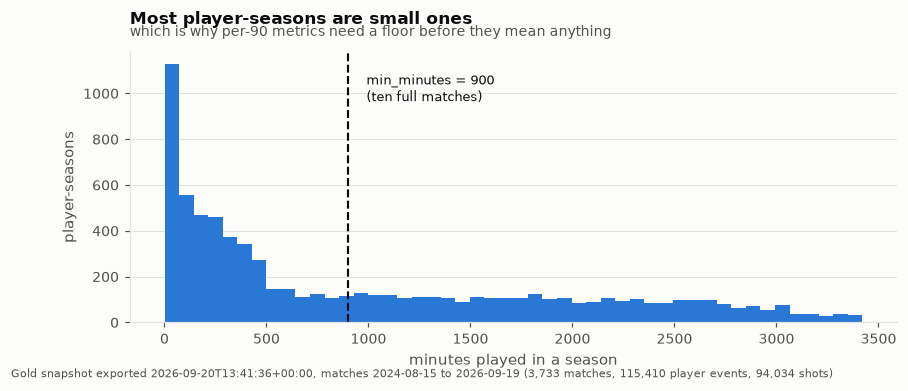

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(season_minutes["minutes"], bins=48, color=viz.ACCENT, linewidth=0)
ax.axvline(900, color=viz.INK, linewidth=1.4, linestyle="--")
ax.annotate(
    "min_minutes = 900\n(ten full matches)",
    xy=(900, ax.get_ylim()[1] * 0.92),
    xytext=(12, 0),
    textcoords="offset points",
    fontsize=8.5,
    color=viz.INK,
    va="top",
)
ax.set_xlabel("minutes played in a season")
ax.set_ylabel("player-seasons")
ax.grid(axis="x", visible=False)
viz.title_block(
    ax,
    "Most player-seasons are small ones",
    "which is why per-90 metrics need a floor before they mean anything",
)
viz.annotate_source(ax, snap.citation())
plt.show()

The distribution is heavily weighted towards small samples — squad players,
mid-season arrivals, injuries. A 900-minute floor keeps roughly the regular
starters, and every chart built on a per-90 says so.

Note that the season here is derived from `match_date` with an August cutoff,
because **only `fact_matches` carries `season`** (trap 5). That derivation
belongs in one dbt macro, not repeated in each model.

## The answer

**What is in the snapshot.** Two complete big-5 seasons plus a third in progress,
across the five leagues, with match results from Football-Data and expected-goals
measures from Understat. The volumes and the date range are printed at the top of
this notebook and carried in `manifest.json`; every analysis in this repository
cites that same line.

**Which traps are actually present.** Not all of them, and one is different from
how it was documented:

| Trap | In this snapshot | What it costs if ignored |
|---|---|---|
| 1, 2 — SCD Type 2 players | **Yes** — 934 players have more than one version, one has six | A transferred player's season split in half: 34 goals read as 18 |
| 3 — `Unknown` member at key 0 | **Yes** — 64 matches have `referee_key = 0` (1.7%) | An invented official credited with dozens of matches |
| 4 — nullable `match_key` | **No** — zero orphans today, but the columns stay nullable | Goals silently dropped by an inner join |
| 6 — scores null unless `FINISHED` | **No** — no match has a null score | — |
| 6′ — **status is not a clean filter** | **Yes** — 3 `AWARDED`, 1 `POSTPONED` | Two clubs read 33 played in a 34-match season |
| 7 — null xG is not zero | **Yes** — 12 unpaired matches (0.32%) | Every xG average dragged towards zero |
| 10 — normalized coordinates | **Confirmed correct** | A shot map drawn backwards |
| 11 — source strings | **Yes** — incl. `MissedShots`, `OwnGoal` | A filter that silently matches nothing |
| 13 — one fixture, two rows | **Yes** — 10 split fixtures | A club's match count off by one |
| 14 — duplicated shots | **Yes** — 46 surplus rows in 2 La Liga matches | Shot volume and 5.9 xG double there |

**The one correction.** `CLAUDE.md` says to filter on `status = 'FINISHED'` for
results-based metrics. That is very slightly wrong in both directions: no score
is null, and three abandoned-then-`AWARDED` matches were really played and really
counted. The filter is **`status IN ('FINISHED', 'AWARDED')`**, which keeps those
three and still excludes the postponed fixture that carries a phantom `0-0`.
Section 9 shows the two clubs whose played count is wrong without it.

**The rules this establishes**, each stated in full beside its section above:
aggregate players by `understat_player_id`; read a player's club from the event
fact; exclude key `0` explicitly and report what that removed; filter
`status IN ('FINISHED', 'AWARDED')` for anything results-based; never coalesce
null xG to zero; filter `football_data_match_id IS NOT NULL` when counting
matches but not when totalling player goals; deduplicate shots on their shape
rather than their id; derive `season` from `match_date` with an August cutoff, in
one macro; and apply a minutes floor to every per-90.

**Caveats on this profile.**

- It describes *one snapshot*. The newest season grows with every re-export, so
  these counts are a point-in-time reading. The trap-4 count in particular is
  zero *today* — the dbt models test it rather than assume it.
- It checks the traps that are documented, and found one more. It cannot rule out
  ones nobody has thought of. The strongest evidence that the data is sound is
  external: Part 1's quality suite passes with 0 errors, and 2024/25's final
  tables, top scorers and penalty xG all reconcile against the real world —
  Bayern's 82 points come out exactly right above.
- `dim_players` history begins inside the loaded range, so `valid_from` is a
  first-seen date and never a transfer date.
- Possession, passes and tackles are **not in Gold at all**, and stadium city and
  capacity are always null. No metric here can be designed around them.
- Nothing here is causal. These are counts and coverage checks, not effects.

**What comes next.** These rules become the dbt staging and intermediate layer —
in particular `int_team_matches`, one row per team per counting match, which is
the foundation every team metric is a `GROUP BY` over. The status filter above is
the first thing it has to get right.